In [1]:
# Create the Environment by Importing necessary frameworks, libraries and modules Nadam with sig and _seresnet34
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau, CSVLogger, TensorBoard
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import CustomObjectScope
import matplotlib.pyplot as plt
from tensorflow import keras
import tensorflow as tf
from tqdm import tqdm
from glob import glob
import numpy as np
import cv2
import os
os.environ["SM_FRAMEWORK"] = "tf.keras"

# Install Segmentation Models needed
!pip install segmentation-models
import segmentation_models as sm

# Import Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Hyperparameters
batch = 8
lr = 1e-4
epochs = 20

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.7/50.7 kB 1.4 MB/s eta 0:00:00
Segmentation Models: using `tf.keras` framework.
Mounted at /content/drive


1000
1000
training size is 700
valid size is 200
testing size is 100


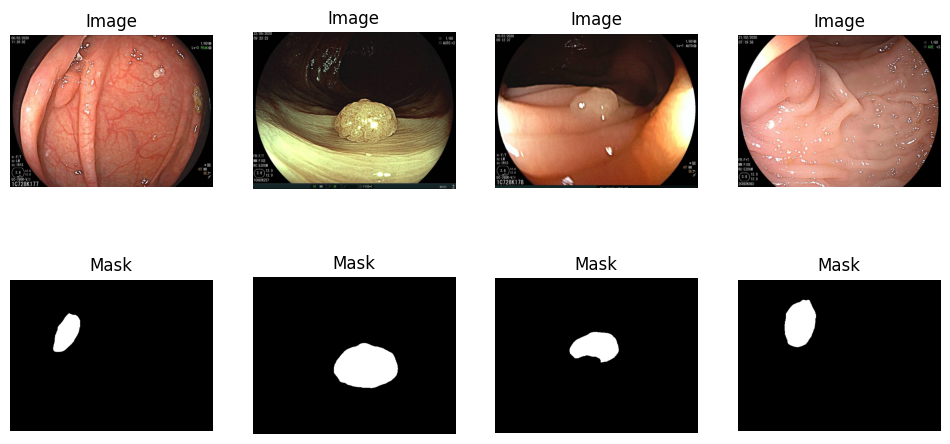

258434480/258434480 [==============================] - 1s 0us/step
Epoch 1/50
88/88 [==============================] - ETA: 0s - loss: 0.5019 - acc: 0.8139 - recall: 0.6000 - precision: 0.1668 - iou: 0.0824

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


88/88 [==============================] - 433s 3s/step - loss: 0.5019 - acc: 0.8139 - recall: 0.6000 - precision: 0.1668 - iou: 0.0824 - val_loss: 1.6716 - val_acc: 0.5315 - val_recall: 0.9905 - val_precision: 0.1136 - val_iou: 0.1012 - lr: 1.0000e-04
Epoch 2/50
88/88 [==============================] - 94s 1s/step - loss: 0.2751 - acc: 0.9750 - recall: 0.7196 - precision: 0.8190 - iou: 0.1464 - val_loss: 0.4778 - val_acc: 0.9195 - val_recall: 0.9667 - val_precision: 0.4350 - val_iou: 0.1557 - lr: 1.0000e-04
Epoch 3/50
88/88 [==============================] - 91s 1s/step - loss: 0.1967 - acc: 0.9823 - recall: 0.7951 - precision: 0.8916 - iou: 0.1973 - val_loss: 0.2550 - val_acc: 0.9725 - val_recall: 0.9311 - val_precision: 0.7292 - val_iou: 0.2156 - lr: 1.0000e-04
Epoch 4/50
88/88 [==============================] - 93s 1s/step - loss: 0.1455 - acc: 0.9861 - recall: 0.8435 - precision: 0.9186 - iou: 0.2533 - val_loss: 0.1599 - val_acc: 0.9836 - val_recall: 0.9007 - val_precision: 0.8648 -

In [2]:
def load_data(path):
    test_split = 0.1
    valid_split = 0.2
    images = sorted(glob(os.path.join(path, "images/*")))
    masks = sorted(glob(os.path.join(path, "masks/*")))
    print(len(images))
    print(len(masks))
    total_size = len(images)
    valid_size = int(valid_split * total_size)
    test_size = int(test_split * total_size)
    train_x, valid_x = train_test_split(images, test_size=valid_size, random_state=42)
    train_y, valid_y = train_test_split(masks, test_size=valid_size, random_state=42)
    train_x, test_x = train_test_split(train_x, test_size=test_size, random_state=42)
    train_y, test_y = train_test_split(train_y, test_size=test_size, random_state=42)
    return (train_x, train_y), (valid_x, valid_y), (test_x, test_y)

def read_image(path):
    path = path.decode()
    x = cv2.imread(path, cv2.IMREAD_COLOR)
    if x is None:
        raise FileNotFoundError(f"Could not read image from: {path}")
    x = cv2.resize(x, (256, 256))
    x = x / 255.0
    return x

def read_mask(path):
    path = path.decode()
    x = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if x is None:
        raise FileNotFoundError(f"Could not read mask from: {path}")
    x = cv2.resize(x, (256, 256))
    x = x / 255.0
    x = np.expand_dims(x, axis=-1)
    return x

def tf_parse(x, y):
    def _parse(x, y):
        x = read_image(x)
        y = read_mask(y)
        return x, y
    x, y = tf.numpy_function(_parse, [x, y], [tf.float64, tf.float64])
    x.set_shape([256, 256, 3])
    y.set_shape([256, 256, 1])
    return x, y

def tf_dataset(x, y, batch=8):
    dataset = tf.data.Dataset.from_tensor_slices((x, y))
    dataset = dataset.map(tf_parse)
    dataset = dataset.batch(batch)
    dataset = dataset.repeat()
    return dataset

def iou(y_true, y_pred):
    def f(y_true, y_pred):
        intersection = (y_true * y_pred).sum()
        union = y_true.sum() + y_pred.sum() - intersection
        x = (intersection + 1e-15) / (union + 1e-15)
        x = x.astype(np.float32)
        return x
    return tf.numpy_function(f, [y_true, y_pred], tf.float32)

if __name__ == "__main__":
    # Load data
    path = r"/content/drive/MyDrive/GI_CR_Polyp_Segmentation/bkai_igh_neopoly"

    (train_x, train_y), (valid_x, valid_y), (test_x, test_y) = load_data(path)
    print(f"training size is {len(train_x)}")
    print(f"valid size is {len(valid_x)}")
    print(f"testing size is {len(test_x)}")

    # Load and preprocess some images and masks for display
    sample_images = train_x[:4] + valid_x[:4]  # 4 training and 4 validation images
    sample_masks = train_y[:4] + valid_y[:4]  # 4 training and 4 validation masks

    plt.figure(figsize=(12, 9))

    for i in range(8):
        plt.subplot(3, 4, i + 1)
        if i < 4:
            img = cv2.imread(sample_images[i])
        else:
            img = cv2.imread(sample_masks[i - 4])
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        if i < 4:
            plt.title("Image")
        else:
            plt.title("Mask")
        plt.axis("off")

    plt.show()

    train_dataset = tf_dataset(train_x, train_y, batch=batch)
    valid_dataset = tf_dataset(valid_x, valid_y, batch=batch)

    # Create the U-Net model
    BACKBONE = 'efficientnetb7'  # You can change this to your desired backbone
    model = sm.Linknet(BACKBONE, encoder_weights='imagenet', activation='sigmoid', classes=1, input_shape=(256, 256, 3))
    opt = tf.keras.optimizers.Adam(lr)
    metrics = ["acc", tf.keras.metrics.Recall(), tf.keras.metrics.Precision(), iou]
    model.compile(loss="binary_crossentropy", optimizer=opt, metrics=metrics)

    callbacks = [
        ModelCheckpoint("/content/drive/MyDrive/GI_CR_Polyp_Segmentation/Coding/GI_CR_Polyp_Seg_Linknet_EfficientNetB7_Adam_BKAI.h5"),
        ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=4),
        CSVLogger("/content/drive/MyDrive/GI_CR_Polyp_Segmentation/Coding/GI_CR_Polyp_Seg_Linknet_EfficientNetB7_Adam_BKAI.csv"),
        TensorBoard(),
        EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=False,min_delta = 0)
    ]

    train_steps = len(train_x)//batch
    valid_steps = len(valid_x)//batch

    if len(train_x) % batch != 0:
        train_steps += 1
    if len(valid_x) % batch != 0:
        valid_steps += 1

    history=model.fit(train_dataset,
        validation_data=valid_dataset,
        epochs=50,
        steps_per_epoch=train_steps,
        validation_steps=valid_steps,
        callbacks=callbacks)


In [3]:
def read_image(path):
    x = cv2.imread(path, cv2.IMREAD_COLOR)
    x = cv2.resize(x, (256, 256))
    x = x/255.0
    return x

def read_mask(path):
    x = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    x = cv2.resize(x, (256, 256))
    x = np.expand_dims(x, axis=-1)
    return x

def mask_parse(mask):
    mask = np.squeeze(mask)
    mask = [mask, mask, mask]
    mask = np.transpose(mask, (1, 2, 0))
    return mask

if True:

    with CustomObjectScope({'iou': iou}):
        model = tf.keras.models.load_model("/content/drive/MyDrive/GI_CR_Polyp_Segmentation/Coding/GI_CR_Polyp_Seg_Linknet_EfficientNetB7_Adam_BKAI.h5")

    for i, (x, y) in tqdm(enumerate(zip(test_x[:10], test_y[:10])), total=len(test_x)):
        x = read_image(x)
        y = read_mask(y)
        y_pred = model.predict(np.expand_dims(x, axis=0))[0] > 0.5
        h, w, _ = x.shape
        white_line = np.ones((h, 10, 3)) * 255.0

        # Prepare images for visualization
        original_image = x * 255.0
        ground_truth_mask = mask_parse(y)
        predicted_mask = mask_parse(y_pred) * 255.0

        all_images = [original_image.astype(np.uint8), white_line, ground_truth_mask, white_line, predicted_mask]

        # Display the images using matplotlib
        plt.figure(figsize=(15, 5))
        plt.subplot(1, 3, 1)
        plt.imshow(cv2.cvtColor(all_images[0], cv2.COLOR_BGR2RGB))  # Convert to RGB for correct display
        plt.title('Original Image')
        plt.axis('off')

        plt.subplot(1, 3, 2)
        plt.imshow(ground_truth_mask)
        plt.title('Ground Truth Mask')
        plt.axis('off')

        plt.subplot(1, 3, 3)
        plt.imshow(predicted_mask.astype(np.uint8))
        plt.title('Predicted Mask')
        plt.axis('off')

        plt.tight_layout()
        plt.show()

Output hidden; open in https://colab.research.google.com to view.

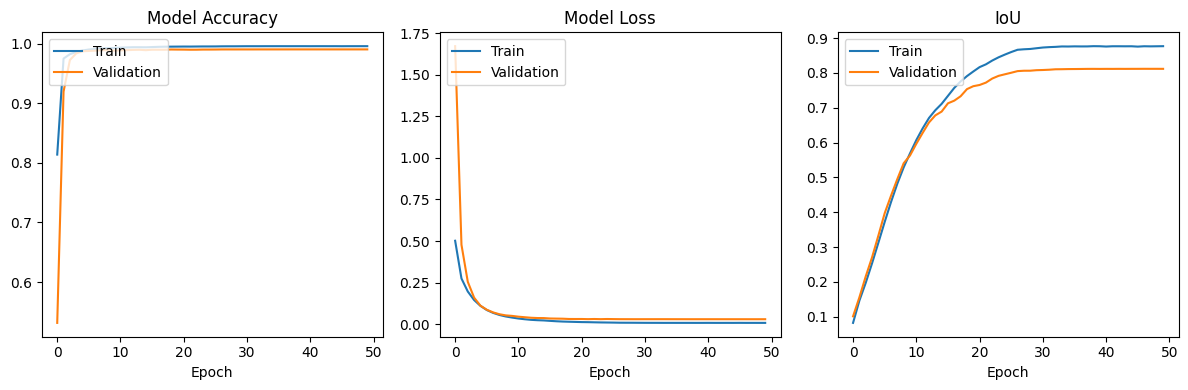

In [4]:
import matplotlib.pyplot as plt

def plot_training_history(history):
    # Plot training & validation accuracy values
    plt.figure(figsize=(12, 4))
    plt.subplot(131)
    plt.plot(history.history['acc'])
    plt.plot(history.history['val_acc'])
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')

    # Plot training & validation loss values
    plt.subplot(132)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')

    # Plot training & validation IoU (Custom Metric)
    plt.subplot(133)
    plt.plot(history.history['iou'])
    plt.plot(history.history['val_iou'])
    plt.title('IoU')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')

    plt.tight_layout()
    plt.show()

# Assuming you have already compiled and trained your model

# Plot the training history
plot_training_history(history)


In [5]:
import numpy as np
from sklearn.metrics import fowlkes_mallows_score
from tqdm import tqdm
from skimage.measure import shannon_entropy

# Function to calculate Dice Coefficient (F1 score)
def dice_coefficient(y_true, y_pred):
    intersection = np.sum(y_true * y_pred)
    union = np.sum(y_true) + np.sum(y_pred)
    dice = (2.0 * intersection) / (union + 1e-7)
    return dice

# Function to calculate Intersection over Union (IoU)
def intersection_over_union(y_true, y_pred):
    intersection = np.sum(y_true * y_pred)
    union = np.sum(y_true) + np.sum(y_pred) - intersection
    iou = (intersection + 1e-7) / (union + 1e-7)
    return iou

# Function to calculate Sørensen-Dice Coefficient (SM)
def sorensen_dice_coefficient(y_true, y_pred):
    intersection = np.sum(y_true * y_pred)
    denominator = np.sum(y_true) + np.sum(y_pred)
    sm = (2.0 * intersection) / (denominator + 1e-7)
    return sm
def jaccard_index(y_true, y_pred):
    intersection = np.sum(y_true * y_pred)
    union = np.sum(np.maximum(y_true, y_pred))  # Union is the maximum of the two masks
    jaccard = intersection / (union + 1e-7)  # Adding a small constant to avoid division by zero
    return jaccard



# Load the model
with CustomObjectScope({'iou': iou}):
    model = tf.keras.models.load_model(r"/content/drive/MyDrive/GI_CR_Polyp_Segmentation/Coding/GI_CR_Polyp_Seg_Linknet_EfficientNetB7_Adam_BKAI.h5")

# Initialize lists to store individual metric values
dice_scores = []
iou_scores = []
fm_scores = []
sm_scores = []
jaccard_scores = []

# Iterate through test images
for i, (x, y) in tqdm(enumerate(zip(test_x, test_y)), total=len(test_x)):
    x = read_image(x)
    y_true = read_mask(y)
    y_pred = model.predict(np.expand_dims(x, axis=0))[0] > 0.5

    # Convert the masks to binary format for metrics calculation
    true_mask_binary = (y_true.squeeze() > 0.5).astype(np.uint8)
    predicted_mask_binary = (y_pred.squeeze() > 0.5).astype(np.uint8)

    # Calculate metrics for the current image
    dice_scores.append(dice_coefficient(true_mask_binary, predicted_mask_binary))
    iou_scores.append(intersection_over_union(true_mask_binary, predicted_mask_binary))

    # Flatten the masks for FM calculation
    true_mask_flat = true_mask_binary.flatten()
    predicted_mask_flat = predicted_mask_binary.flatten()

    # Calculate Fowlkes-Mallows Index (FM)
    fm_scores.append(fowlkes_mallows_score(true_mask_flat, predicted_mask_flat))

    # Calculate Sørensen-Dice Coefficient (SM)
    sm_scores.append(sorensen_dice_coefficient(true_mask_binary, predicted_mask_binary))

    # Calculate Mean Absolute Error (MAE)
    jaccard_scores.append(jaccard_index(y_true, y_pred))

    # Calculate Entropy (EM)

# Calculate the mean of each metric
mean_dice = np.mean(dice_scores)
mean_iou = np.mean(iou_scores)
mean_fm = np.mean(fm_scores)
mean_sm = np.mean(sm_scores)
mean_js = np.mean(jaccard_scores)

# Print the mean metrics
print("Mean Dice Coefficient:", mean_dice)
print("Mean Intersection over Union:", mean_iou)
print("Mean Fowlkes-Mallows Index (FM):", mean_fm)
print("Mean Sørensen-Dice Coefficient (SM):", mean_sm)
print("Mean Jaccard Index:", mean_js)

  0%|          | 0/100 [00:00<?, ?it/s]

1/1 [==============================] - 6s 6s/step


  1%|          | 1/100 [00:06<10:21,  6.28s/it]

1/1 [==============================] - 0s 49ms/step


  2%|▏         | 2/100 [00:06<04:22,  2.68s/it]

1/1 [==============================] - 0s 44ms/step


... (192 outputs left out)

 99%|█████████▉| 99/100 [00:43<00:00,  3.00it/s]

1/1 [==============================] - 0s 67ms/step


100%|██████████| 100/100 [00:43<00:00,  2.29it/s]

Mean Dice Coefficient: 0.8771243989153185
Mean Intersection over Union: 0.8114210733675361
Mean Fowlkes-Mallows Index (FM): 0.9926046482848083
Mean Sørensen-Dice Coefficient (SM): 0.8771243989153185
Mean Jaccard Index: 0.8881367187827732


In [ ]:
pip install gradio

In [ ]:
import gradio as gr
import os
import numpy as np
import cv2
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.utils import CustomObjectScope
# Define your read_image and mask_parse functions here
with CustomObjectScope({'iou': iou}):
    model = tf.keras.models.load_model("uunet.h5")

def read_image(input_data):
    if isinstance(input_data, str):  # If input_data is a string, assume it's a file path
        x = cv2.imread(input_data, cv2.IMREAD_COLOR)
    else:  # If input_data is not a string, assume it's image data
        x = input_data

    x = cv2.resize(x, (256, 256))
    x = x / 255.0
    return x

def mask_parse(mask):
    mask = np.squeeze(mask)
    mask = [mask, mask, mask]
    mask = np.transpose(mask, (1, 2, 0))
    return mask

# Function to make predictions using the loaded model
def predict_mask(image):
    # Preprocess the input image
    x = read_image(image)

    # Make a prediction for the input image
    y_pred = model.predict(np.expand_dims(x, axis=0))[0] > 0.5

    # Prepare the predicted mask for visualization
    predicted_mask = mask_parse(y_pred) * 255.0


    return predicted_mask.astype(np.uint8)

# Gradio Interface
iface = gr.Interface(
    fn=predict_mask,
    inputs=gr.Image(),  # Image input component
    outputs=gr.Image(),  # Image output component
    live=True,
    title="Enter the photo to do the segmentation",  # Custom title
    css="""
        .gradio-component, .gradio-image {
            width: 256px;
            height: 256px;
            justify-content: center;
            object-fit: contain;
        }
        img {
            width: 256px;
            height: 256px;
            justify-content: center;
            object-fit: contain;
        }
    """
)


# Launch the Gradio Interface
iface.launch()